# <center>**Chapter 11 - MLP Sonar Classification**<center>

## **1. Chuẩn bị môi trường**

Import các thư viện cần thiết, cố định random seed và chọn GPU nếu có. Các tham số huấn luyện được đặt tập trung để dễ theo dõi.

In [1]:
from copy import deepcopy
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import accuracy_score, auc, roc_curve
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import LabelEncoder
from torch.utils.data import DataLoader, TensorDataset

In [2]:
SEED = 42
TEST_SIZE = 0.20
EPOCHS = 200
BATCH_SIZE = 16
LEARNING_RATE = 0.0001

# Cố định seed để các lần chia dữ liệu và khởi tạo mô hình có thể tái lập.
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch: {torch.__version__} | Device: {DEVICE}")

PyTorch: 2.14.0+cpu | Device: cpu


## **2. Đọc và xử lý dữ liệu**

Tập dữ liệu không có header, gồm 60 đặc trưng và một nhãn cuối. Notebook ưu tiên `sonar.csv`; trong repository, dữ liệu gốc hiện có tên `sonar.all-data`, nên tệp đó được dùng làm phương án thay thế. `LabelEncoder` mã hóa theo thứ tự chữ cái: `M = 0`, `R = 1`.

Tách riêng 20% làm test trước khi cross-validation để tập test không ảnh hưởng đến việc chọn kiến trúc.

In [3]:
# Xác định đường dẫn dữ liệu dù notebook chạy từ thư mục của nó hay thư mục gốc của repository.
relative_data_dir = Path("data/connectionist_bench_sonar_minesvsrocks")
if relative_data_dir.is_dir():
    DATA_DIR = relative_data_dir
else:
    candidates = list(
        Path.cwd().glob(
            "Bu*/Lab05a*/data/connectionist_bench_sonar_minesvsrocks"
        )
    )
    if not candidates:
        raise FileNotFoundError(
            "Cannot find data/connectionist_bench_sonar_minesvsrocks. "
            "Run this notebook from its folder or the repository root."
        )
    DATA_DIR = candidates[0]

DATA_PATH = DATA_DIR / "sonar.csv"
if not DATA_PATH.is_file():
    DATA_PATH = DATA_DIR / "sonar.all-data"
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Neither sonar.csv nor sonar.all-data was found in {DATA_DIR.resolve()}"
    )

In [4]:
dataframe = pd.read_csv(DATA_PATH, header=None)
if dataframe.shape[1] != 61:
    raise ValueError(
        f"Expected 61 columns (60 features + label), got {dataframe.shape[1]}."
    )

features = dataframe.iloc[:, :-1].to_numpy(dtype=np.float32)
labels_text = dataframe.iloc[:, -1].astype(str).to_numpy()
label_encoder = LabelEncoder()
# Mã hóa nhãn theo thứ tự chữ cái: M = 0 và R = 1.
labels = label_encoder.fit_transform(labels_text).astype(np.int64)
if len(label_encoder.classes_) != 2:
    raise ValueError(f"Expected two classes, got {label_encoder.classes_}.")

label_mapping = dict(
    zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_))
)
print(f"Data file: {DATA_PATH}")
print(f"Feature matrix shape: {features.shape}")
print(f"Label mapping: {label_mapping}")

Data file: data\connectionist_bench_sonar_minesvsrocks\sonar.all-data
Feature matrix shape: (208, 60)
Label mapping: {'M': np.int64(0), 'R': np.int64(1)}


In [5]:
all_indices = np.arange(len(labels))

# Giữ nguyên tỷ lệ hai lớp và tách test trước để tránh rò rỉ vào cross-validation.
train_indices, test_indices = train_test_split(
    all_indices,
    test_size=TEST_SIZE,
    random_state=SEED,
    stratify=labels,
)

X = torch.tensor(features, dtype=torch.float32, device=DEVICE)
y = torch.tensor(labels, dtype=torch.float32, device=DEVICE).reshape(-1, 1)
train_index_tensor = torch.as_tensor(train_indices, dtype=torch.long, device=DEVICE)
test_index_tensor = torch.as_tensor(test_indices, dtype=torch.long, device=DEVICE)

X_train, y_train = X[train_index_tensor], y[train_index_tensor]
X_test, y_test = X[test_index_tensor], y[test_index_tensor]

print(f"Training samples: {len(X_train)} | Test samples: {len(X_test)}")

Training samples: 166 | Test samples: 42


## **3. Định nghĩa mô hình và so sánh số tham số**

- **Wide**: một tầng ẩn gồm 180 nơ-ron.
- **Deep**: ba tầng ẩn liên tiếp, mỗi tầng gồm 60 nơ-ron.

Các tầng ẩn dùng ReLU; tầng đầu ra có một nơ-ron với Sigmoid để trả về xác suất lớp dương.

In [6]:
class Wide(nn.Module):
    """MLP có một tầng ẩn gồm 180 nơ-ron."""

    def __init__(self) -> None:
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(60, 180),
            nn.ReLU(),
            nn.Linear(180, 1),
            nn.Sigmoid(),
        )

    def forward(self, inputs: torch.Tensor) -> torch.Tensor:
        return self.network(inputs)

class Deep(nn.Module):
    """MLP có ba tầng ẩn, mỗi tầng gồm 60 nơ-ron."""

    def __init__(self) -> None:
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(60, 60),
            nn.ReLU(),
            nn.Linear(60, 60),
            nn.ReLU(),
            nn.Linear(60, 60),
            nn.ReLU(),
            nn.Linear(60, 1),
            nn.Sigmoid(),
        )

    def forward(self, inputs: torch.Tensor) -> torch.Tensor:
        return self.network(inputs)

def count_parameters(model: nn.Module) -> int:
    return sum(parameter.numel() for parameter in model.parameters())

wide_parameters = count_parameters(Wide())
deep_parameters = count_parameters(Deep())
print(f"Wide parameters: {wide_parameters:,}")
print(f"Deep parameters: {deep_parameters:,}")

Wide parameters: 11,161
Deep parameters: 11,041


## **4. Hàm huấn luyện và lưu trọng số tốt nhất**

Sau mỗi epoch, tính accuracy trên validation set. Lưu bản sao `state_dict` tại epoch đạt accuracy cao nhất và khôi phục các trọng số này trước khi trả mô hình. Quá trình huấn luyện sử dụng `BCELoss` và Adam với learning rate `0.0001`.

In [7]:
def model_train(
    model: nn.Module,
    train_features: torch.Tensor,
    train_labels: torch.Tensor,
    validation_features: torch.Tensor,
    validation_labels: torch.Tensor,
    epochs: int = EPOCHS,
    batch_size: int = BATCH_SIZE,
) -> tuple[nn.Module, float, int]:
    """Huấn luyện mô hình và khôi phục trọng số từ epoch có accuracy validation cao nhất."""
    model = model.to(DEVICE)
    train_loader = DataLoader(
        TensorDataset(train_features, train_labels),
        batch_size=batch_size,
        shuffle=True,
    )
    criterion = nn.BCELoss()
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
    # Lưu bản sao trọng số để cuối cùng khôi phục epoch tốt nhất trên validation.
    best_accuracy = -1.0
    best_epoch = 0
    best_weights = deepcopy(model.state_dict())

    for epoch in range(1, epochs + 1):
        model.train()
        for batch_features, batch_labels in train_loader:
            optimizer.zero_grad()
            probabilities = model(batch_features)
            loss = criterion(probabilities, batch_labels)
            loss.backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            validation_probabilities = model(validation_features)
            validation_predictions = (validation_probabilities >= 0.5).float()
            validation_accuracy = (
                validation_predictions.eq(validation_labels).float().mean().item()
            )

        if validation_accuracy > best_accuracy:
            best_accuracy = validation_accuracy
            best_epoch = epoch
            best_weights = deepcopy(model.state_dict())

    model.load_state_dict(best_weights)
    return model, best_accuracy, best_epoch

## **5. Stratified 5-fold cross-validation**

Mỗi fold giữ tỷ lệ hai lớp gần với toàn bộ tập train. So sánh Wide và Deep bằng accuracy validation trung bình; đồng thời ghi lại epoch tốt nhất của từng fold để chọn số epoch khi huấn luyện lại.

In [8]:
# Dùng cùng các fold để so sánh công bằng hai kiến trúc.
MODEL_CLASSES = {"Wide": Wide, "Deep": Deep}
cross_validator = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_results: dict[str, list[float]] = {name: [] for name in MODEL_CLASSES}
best_epochs: dict[str, list[int]] = {name: [] for name in MODEL_CLASSES}

for model_name, model_class in MODEL_CLASSES.items():
    print(f"\n--- {model_name}: 5-fold cross-validation ---")
    split_iterator = cross_validator.split(
        X_train.cpu().numpy(), y_train.cpu().numpy().ravel()
    )

    for fold, (fold_train_idx, fold_val_idx) in enumerate(split_iterator, start=1):
        fold_train_tensor = torch.as_tensor(
            fold_train_idx, dtype=torch.long, device=DEVICE
        )
        fold_val_tensor = torch.as_tensor(
            fold_val_idx, dtype=torch.long, device=DEVICE
        )
        _, fold_accuracy, fold_best_epoch = model_train(
            model_class(),
            X_train[fold_train_tensor],
            y_train[fold_train_tensor],
            X_train[fold_val_tensor],
            y_train[fold_val_tensor],
        )
        cv_results[model_name].append(fold_accuracy)
        best_epochs[model_name].append(fold_best_epoch)
        print(
            f"Fold {fold}: validation accuracy={fold_accuracy:.4f} "
            f"(best epoch {fold_best_epoch})"
        )

print("\nCross-validation summary:")
for model_name, scores in cv_results.items():
    print(
        f"{model_name}: mean accuracy={np.mean(scores):.4f} "
        f"+/- {np.std(scores):.4f}"
    )

# Chọn mô hình theo accuracy validation trung bình, không dùng kết quả test.
selected_name = max(MODEL_CLASSES, key=lambda name: np.mean(cv_results[name]))
selected_class = MODEL_CLASSES[selected_name]
# Median giúp chọn số epoch đại diện, ít bị ảnh hưởng bởi fold bất thường.
final_epochs = max(1, int(np.median(best_epochs[selected_name])))
print(f"\nSelected model: {selected_name}")
print(f"Final training epochs: {final_epochs}")


--- Wide: 5-fold cross-validation ---
Fold 1: validation accuracy=0.7941 (best epoch 150)
Fold 2: validation accuracy=0.8485 (best epoch 136)
Fold 3: validation accuracy=0.7273 (best epoch 180)
Fold 4: validation accuracy=0.8182 (best epoch 75)
Fold 5: validation accuracy=0.7576 (best epoch 158)

--- Deep: 5-fold cross-validation ---
Fold 1: validation accuracy=0.8824 (best epoch 99)
Fold 2: validation accuracy=0.8788 (best epoch 134)
Fold 3: validation accuracy=0.6970 (best epoch 22)
Fold 4: validation accuracy=0.8788 (best epoch 128)
Fold 5: validation accuracy=0.7879 (best epoch 166)

Cross-validation summary:
Wide: mean accuracy=0.7891 +/- 0.0429
Deep: mean accuracy=0.8250 +/- 0.0733

Selected model: Deep
Final training epochs: 128


## **6. Huấn luyện lại mô hình được chọn**

Chọn kiến trúc có mean validation accuracy cao nhất. Dùng median best epoch của 5 fold làm số epoch huấn luyện cuối cùng, sau đó fit trên toàn bộ tập train. Tập test vẫn được giữ riêng cho phần đánh giá tiếp theo.

In [9]:
# Huấn luyện lại trên toàn bộ tập train sau khi đã chọn kiến trúc và số epoch.
final_model = selected_class().to(DEVICE)
final_train_loader = DataLoader(
    TensorDataset(X_train, y_train),
    batch_size=BATCH_SIZE,
    shuffle=True,
)
criterion = nn.BCELoss()
optimizer = optim.Adam(final_model.parameters(), lr=LEARNING_RATE)

for _ in range(final_epochs):
    final_model.train()
    for batch_features, batch_labels in final_train_loader:
        optimizer.zero_grad()
        probabilities = final_model(batch_features)
        loss = criterion(probabilities, batch_labels)
        loss.backward()
        optimizer.step()

print(f"Finished fitting {selected_name} on {len(X_train)} training samples.")

Finished fitting Deep on 166 training samples.


## **7. Inference và đánh giá ROC trên test set**

Dự đoán một vài mẫu test, tính accuracy và vẽ ROC. ROC sử dụng xác suất dự đoán liên tục của lớp dương (`R = 1`), không phải nhãn đã áp dụng ngưỡng.

Test accuracy: 0.8333

Sample predictions (true -> predicted, P(R)):
Sample 1: R -> R, P(R)=0.7218
Sample 2: R -> M, P(R)=0.2549
Sample 3: R -> M, P(R)=0.3110
Sample 4: M -> M, P(R)=0.0665
Sample 5: M -> M, P(R)=0.2051


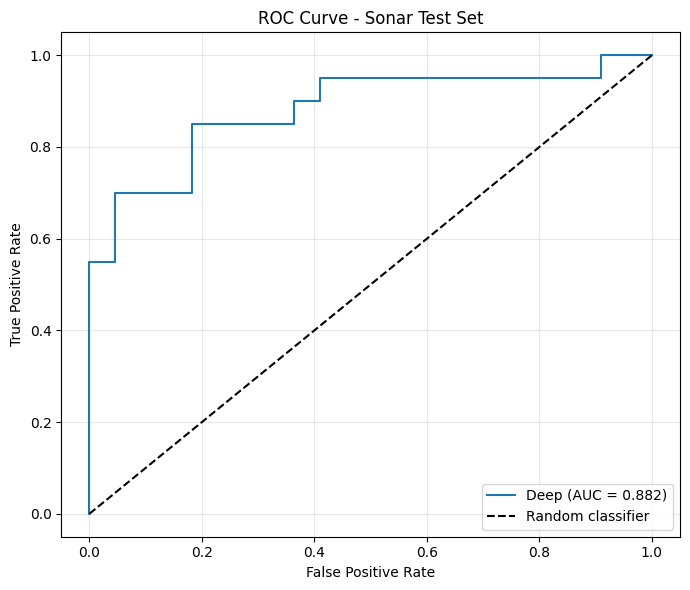

Test ROC-AUC: 0.8818


In [10]:
# Chỉ đánh giá một lần trên test set độc lập; ROC dùng xác suất liên tục.
final_model.eval()
with torch.no_grad():
    test_probabilities = final_model(X_test).cpu().numpy().ravel()

test_labels = y_test.cpu().numpy().ravel().astype(np.int64)
test_predictions = (test_probabilities >= 0.5).astype(np.int64)
print(f"Test accuracy: {accuracy_score(test_labels, test_predictions):.4f}")
print("\nSample predictions (true -> predicted, P(R)):")

for index in range(min(5, len(test_labels))):
    true_label = label_encoder.inverse_transform([test_labels[index]])[0]
    predicted_label = label_encoder.inverse_transform([test_predictions[index]])[0]
    print(
        f"Sample {index + 1}: {true_label} -> {predicted_label}, "
        f"P(R)={test_probabilities[index]:.4f}"
    )

false_positive_rate, true_positive_rate, _ = roc_curve(
    test_labels,
    test_probabilities,
    pos_label=1,
)
roc_auc = auc(false_positive_rate, true_positive_rate)

plt.figure(figsize=(7, 6))
plt.plot(
    false_positive_rate,
    true_positive_rate,
    label=f"{selected_name} (AUC = {roc_auc:.3f})",
)
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Sonar Test Set")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print(f"Test ROC-AUC: {roc_auc:.4f}")

## **8. Tổng kết**

Notebook so sánh hai kiến trúc MLP Wide và Deep trên dữ liệu Sonar. Mô hình được chọn dựa trên accuracy trung bình của stratified 5-fold cross-validation, sau đó huấn luyện lại trên toàn bộ tập train.

Tập test được giữ độc lập để đánh giá cuối cùng. Sau khi chạy notebook, xem `Selected model`, `Test accuracy`, `Test ROC-AUC` và biểu đồ ROC để đối chiếu kết quả phân loại.